In [ ]:
import serial
import MotoricaInterface as mi; assert mi.__version__ == '0.0.8'
import time
import numpy as np
import matplotlib.pyplot as plt

%matplotlib ipympl

In [3]:
mi.utils.list_devices()

,device,name,description,hwid,vid,pid,serial_number,location,manufacturer,product,interface
0,/dev/cu.BLTH,cu.BLTH,n/a,n/a,NaN,NaN,None,None,None,None,None
1,/dev/cu.BoseQC35II,cu.BoseQC35II,n/a,n/a,NaN,NaN,None,None,None,None,None
2,/dev/cu.Bluetooth-Incoming-Port,cu.Bluetooth-Incoming-Port,n/a,n/a,NaN,NaN,None,None,None,None,None
3,/dev/cu.usbmodem1234561,cu.usbmodem1234561,Espressif Device,USB VID:PID=303A:4001 SER=123456 LOCATION=20-3,12346.0,16385.0,123456,20-3,Espressif Systems,Espressif Device,None


In [4]:
ser = serial.Serial(
    port='/dev/cu.usbmodem1234561',
    baudrate=115200,
    timeout=1
)

# Send command to start sampling


`[0x20, 0x08, 0x00, 0x01, 0x00, 0x00, 0x00, 0x01]` - инициализация оптики.  
`[0x60, 0x80, 0x00, 0x01, 0x00, 0x00, 0x0A, 0x02]` - включение/выключение стрима данных.  
`[0xc0, 0x86, 0x00, 0x01, 0x00, 0x00, 0x0A, 0x02]` - по тоннелю команда отправки чекпоинта, но пока эта команда что-то делает только в моих двух ветках.  

In [ ]:
cmd = [
    [0x20, 0x08, 0x00, 0x01, 0x00, 0x00, 0x00, 0x01],
    [0x60, 0x80, 0x00, 0x01, 0x00, 0x00, 0x0A, 0x02],
    # [0xc0, 0x86, 0x00, 0x01, 0x00, 0x00, 0x0A, 0x02],
]

for i in range(len(cmd)):
    data_to_send = bytes(cmd[i])
    ser.write(data_to_send)
    print("Data sent:", data_to_send)
    time.sleep(1)
    response = ser.read(ser.in_waiting)
    print("Response received:", [hex(i) for i in response])
    time.sleep(1)


Data sent: b' \x08\x00\x01\x00\x00\x00\x01'
Response received: []
Data sent: b'`\x80\x00\x01\x00\x00\n\x02'
Response received: []


# Study interbyte timestamp sampling

In [5]:
while ser.in_waiting > 0:
    ser.read(ser.in_waiting)
    time.sleep(0.001)

print(ser.in_waiting)

b = []
ts = []
for i in range(1000):
    b.append(ser.read(1))
    ts.append(time.time())

print(b)
print(ts)


0
[b'\x00', b'\t', b'\x00', b'J', b'\x00', b'\x11', b'\x00', b'\n', b'\x05', b'\xd0', b'\xa6', b'{', b'J', b'\xb8', b'\xbd', b'{', b'J', b'\xcf', b'u', b'B', b'K', b'\x82', b'\x80', b'f', b'K', b'~', b'\xb1', b'D', b'K', b'>', b'B', b'h', b'K', b'\xe8', b'\xf5', b'Z', b'K', b'\x01', b'\x14', b'h', b'K', b'8', b'\xc1', b']', b'K', b'\x92', b'\x92', b'h', b'K', b'\xf4', b'L', b'_', b'K', b'z', b'p', b'O', b'K', b'\xdd', b'\xa2', b'a', b'K', b'x', b'\xa7', b'V', b'K', b'\x0b', b'\x89', b':', b'K', b'\xce', b'4', b'g', b'K', b'\x00', b'\x00', b'\x00', b'\x00', b'\x00', b'\x00', b'\x00', b'\x00', b'\x00', b'\t', b'\x00', b'J', b'\x00', b'*', b'\x00', b'\n', b'\x05', b'`', b'\xa6', b'{', b'J', b'\xb4', b'\xc0', b'{', b'J', b'o', b'y', b'B', b'K', b'o', b'\x80', b'f', b'K', b'/', b'\xa9', b'D', b'K', b'\xe9', b'@', b'h', b'K', b'\xd5', b'\xf4', b'Z', b'K', b'\xd4', b'\x13', b'h', b'K', b'\x8d', b'\xcc', b']', b'K', b'A', b'\x86', b'h', b'K', b'\xa3', b'F', b'_', b'K', b'\xe6', b'z', b'O', b'K

In [6]:
import numpy as np

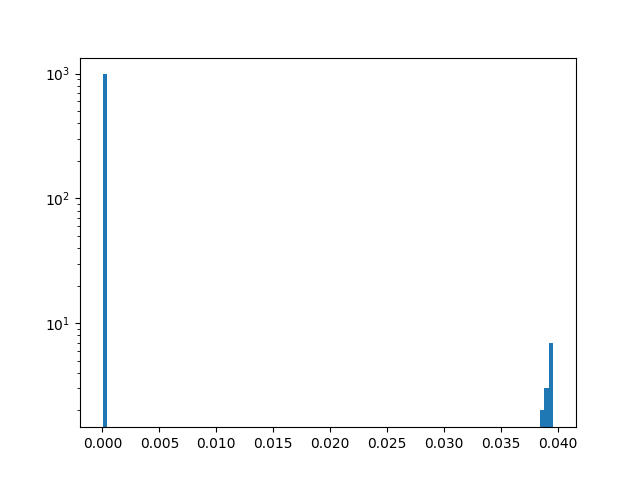

In [15]:
plt.figure()
plt.hist(np.diff(ts), bins=100)
plt.yscale('log')